# `pycalo` demo

This notebook demonstrates the calorimeter tools in `pyutils.pycalo`:

- `CrystalMap`: the crystal map of both calorimeter disks
- `PipeGeometry`: the calibration source pipes, matching `CaloCalibGun`
- `CaloVisualization`: event displays with digis and reco digis highlighted

It then shows how to build your own displays and how to follow the links between calorimeter data products with awkward arrays.

>**Note**: `pycalo` is preliminary and will keep evolving.

## 1. Setup and imports

In [1]:
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.collections import PatchCollection

from pyutils.pycalo import CrystalMap, PipeGeometry, CaloVisualization
from pyutils.pyread import Reader
from pyutils.pyplot import Plot

## 2. The crystal map

`CrystalMap` loads the crystal map packaged with `pyutils` (`pyutils/configs/caloDMAP_nominal.dat`) by default. Crystal IDs run from 0 to 673 on disk 0 and from 674 to 1347 on disk 1, and the positions `xcry`, `ycry` are in mm in the disk frame.

In [2]:
crystal_map = CrystalMap(verbosity=1)
crystal_map.print_map_info()

# The crystals of each disk are stored in a pandas DataFrame
crystal_map.crystals_by_disk[0][["disk", "cryID", "xcry", "ycry"]].head()

[pycrystal] [INFO] Loaded map with 1344 CAL crystals from 2 disks
[pycrystal] [INFO]   Disk 0: 670 crystals
[pycrystal] [INFO]   Disk 1: 674 crystals
[pycrystal] [INFO] Initialized CrystalMap from /exp/mu2e/app/users/sophie/py-tools/pyutils/pyutils/configs/caloDMAP_nominal.dat with verbosity=1
[pycrystal] [INFO] Pipe geometry initialized with 5 pipes
[pycrystal] [INFO] Map Information
[pycrystal] [INFO]   Total crystals: 1344
[pycrystal] [INFO]   Number of disks: 2
[pycrystal] [INFO]   Disk 0: 670 crystals
[pycrystal] [INFO]   Disk 1: 674 crystals


,disk,cryID,xcry,ycry
0,0,550,-137.2,-617.4
1,0,549,-102.9,-617.4
2,0,548,-68.6,-617.4
3,0,547,-34.3,-617.4
4,0,546,0.0,-617.4


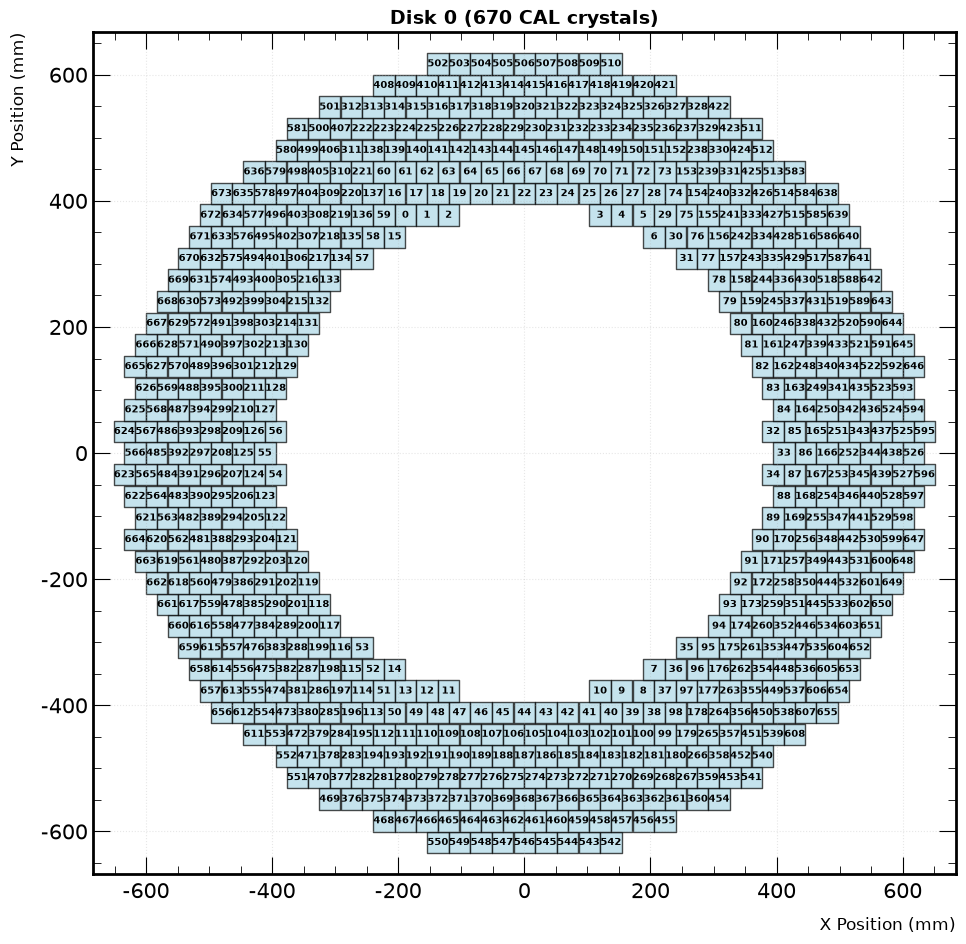

In [3]:
fig = crystal_map.visualize_disk(disk_id=0, figsize=(10, 10))
plt.show()

## 3. Calibration source pipes

`PipeGeometry` holds the calibration source pipe parameters from `calorimeter_CsI_v2.txt`, and reproduces the geometry used by `CaloCalibGun`. Use `show_pipes=True` to overlay the pipes on the crystal map.

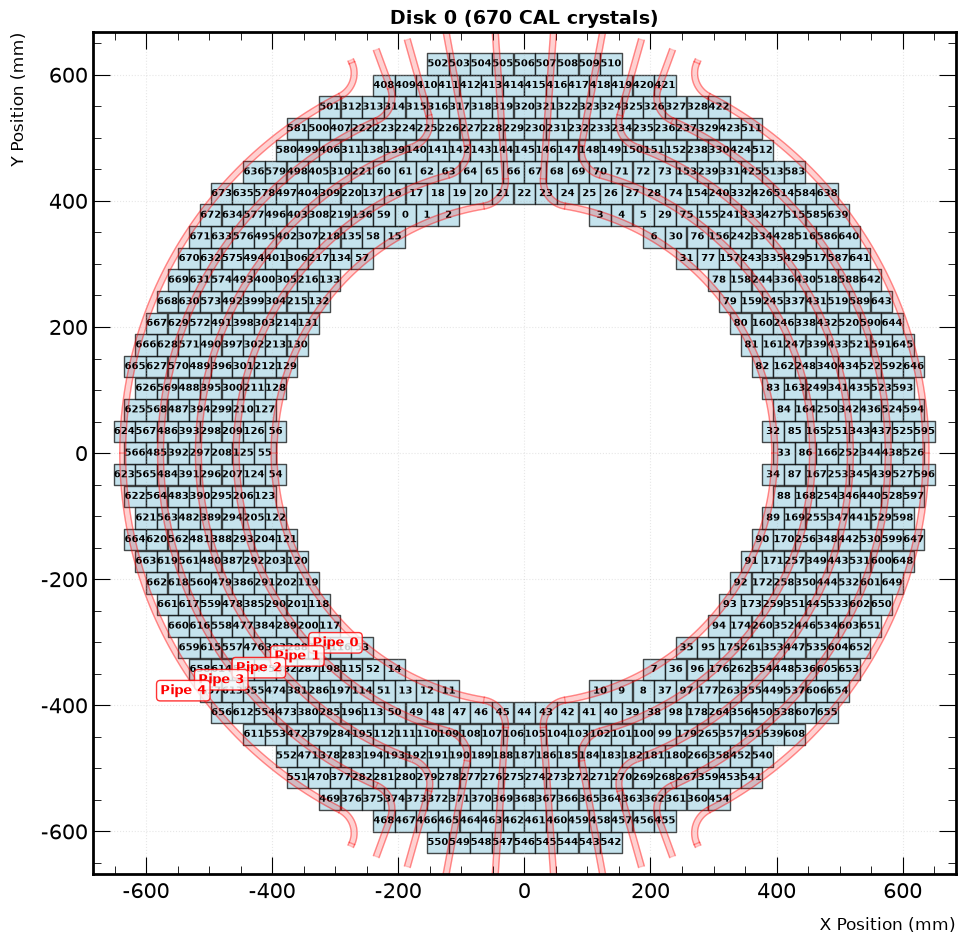

In [4]:
fig = crystal_map.visualize_disk(disk_id=0, show_pipes=True, figsize=(10, 10))
plt.show()

Each pipe is made of three sections: a large torus arc, a small torus arc and a straight section up to the manifold. `pipe_sections()` returns the centreline of each section, which you can use in your own plots:

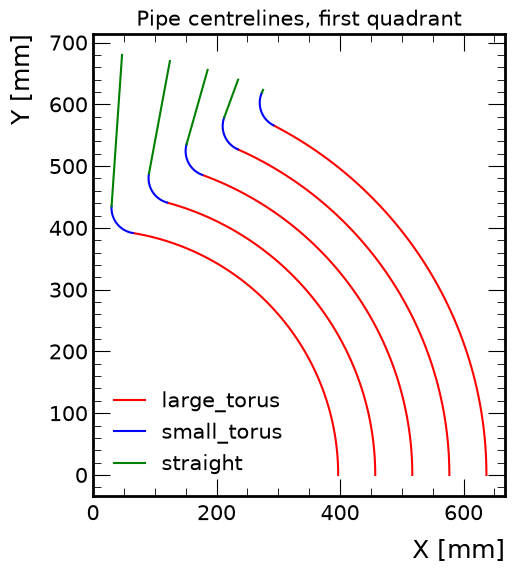

In [5]:
geom = PipeGeometry()
section_colors = {"large_torus": "C0", "small_torus": "C1", "straight": "C2"}

fig, ax = plt.subplots(figsize=(6, 6))
for idx in range(len(geom.pipe_tor_radii)):
    for name, (x, y) in geom.pipe_sections(idx).items():
        ax.plot(x, y, color=section_colors[name], label=name if idx == 0 else None)
ax.set_aspect("equal")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_title("Pipe centrelines, first quadrant")
ax.legend()
plt.show()

## 4. Loading calorimeter data

The calorimeter digi and reco digi branches (`calodigis`, `calorecodigis`) are only written when `EventNtuple` runs with `FillCaloDigis` and `FillCaloRecoDigis` set to `true`, which is not the default. Here we use an ntuple from cosmic run 125329, which has all the calorimeter branches.

This file holds 10M events (15 GB), and `Processor` always reads whole files, so here we open it with `Reader` and read only the first events using uproot's `entry_stop`.

In [6]:
file_name = "/exp/mu2e/data/users/pgirotti/ntuples/mc2/calibrated/ntuple_run125329.root"

branches = [
    "calodigis.SiPMID_",           # SiPM ID of each raw digi
    "calodigis.diskID_",           # Disk of each raw digi
    "calorecodigis.caloDigiIdx_",  # Index of the raw digi each reco digi was made from
    "calorecodigis.eDep_",         # Reco digi energy [MeV]
    "calohits.crystalId_",         # Crystal of each hit
    "calohits.eDep_",              # Hit energy [MeV]
]

reader = Reader(verbosity=1)
with reader.read_file(file_name) as file:
    data = file["EventNtuple/ntuple"].arrays(branches, entry_stop=500, library="ak")

print(f"Loaded {len(data)} events")
data.type.show()

[pyread] [OK] Opened /exp/mu2e/data/users/pgirotti/ntuples/mc2/calibrated/ntuple_run125329.root
Loaded 500 events
500 * {
    "calodigis.SiPMID_": var * int32,
    "calodigis.diskID_": var * int32,
    "calorecodigis.caloDigiIdx_": var * int32,
    "calorecodigis.eDep_": var * float32,
    "calohits.crystalId_": var * int32,
    "calohits.eDep_": var * float32
}


Pick the event with the most digis, and the disk where most of them are:

In [7]:
n_digis = ak.num(data["calodigis.SiPMID_"])
evt_idx = int(ak.argmax(n_digis))
disk = int(np.bincount(ak.to_numpy(data["calodigis.diskID_"][evt_idx])).argmax())

print(f"Event {evt_idx}: {n_digis[evt_idx]} digis, mostly on disk {disk}")

Event 490: 68 digis, mostly on disk 0


## 5. Event display

`CaloVisualization.plot_event_display` draws the crystal grid and highlights the crystals with digis (yellow) and reco digis (cyan). Each crystal is read out by two SiPMs, so the crystal ID is `SiPMID // 2`. Reco digis are located via the raw digi they were made from.

[pycalo_vis] [INFO] Initialised CaloVisualization
[pycalo_vis] [INFO] Loading crystal map from /exp/mu2e/app/users/sophie/py-tools/pyutils/pyutils/configs/caloDMAP_nominal.dat
[pycalo_vis] [INFO] Loaded 1344 CAL crystals from 2 disks
[pycalo_vis] [INFO]   Disk 0: 670 crystals
[pycalo_vis] [INFO]   Disk 1: 674 crystals
[pycalo_vis] [INFO] Initialized pipe geometry with 5 pipes
[pycalo_vis] [INFO] Event 490: Found 68/68 digis on disk 0


[pycalo_vis] [INFO] Drew 670 crystals for disk 0
[pycalo_vis] [INFO] highlight_hit_crystals: Successfully drew 34/34 requested crystals
[pycalo_vis] [INFO] Highlighted 34 crystals for 68 digis on disk 0
[pycalo_vis] [INFO] highlight_hit_crystals: Successfully drew 34/34 requested crystals
[pycalo_vis] [INFO] Highlighted 34 crystals for 69 reco digis on disk 0
[pycalo_vis] [INFO] Drew calibration pipe geometry
[pycalo_vis] [INFO] Set axis limits for disk 0


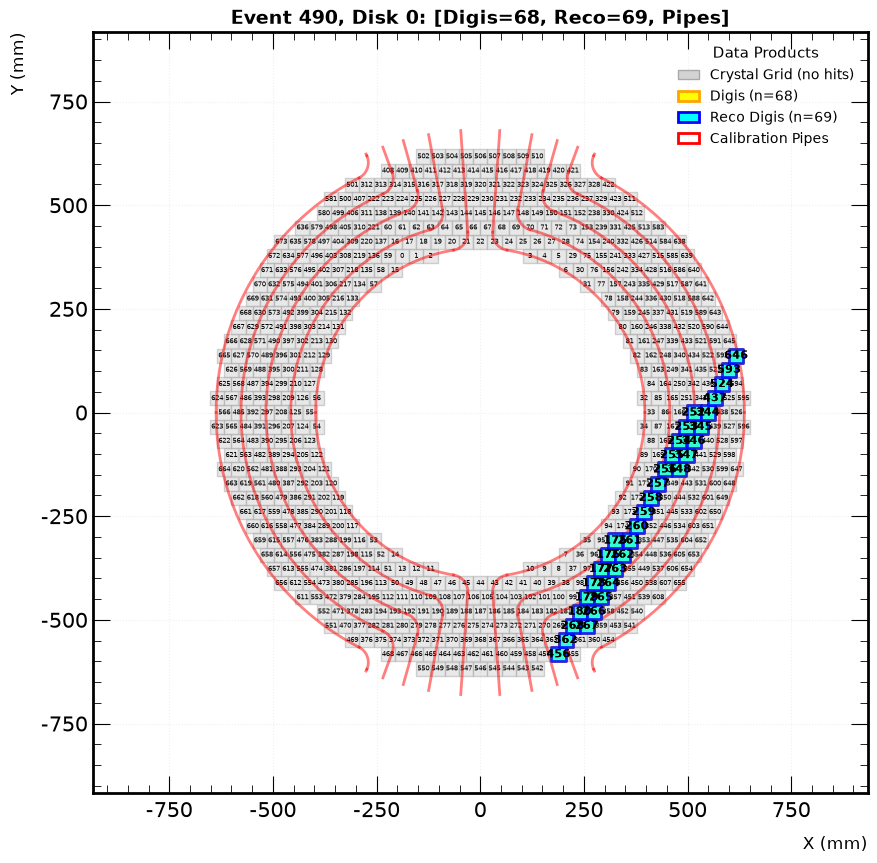

In [8]:
calo_vis = CaloVisualization(verbosity=1)
calo_vis.load_crystal_map()

fig, ax = calo_vis.plot_event_display(
    data=data,
    evt_idx=evt_idx,
    disk=disk,
    show_digis=True,
    show_reco_digis=True,
    show_pipes=True,
    figsize=(10, 10)
)
plt.show()

## 6. Building your own display

The building blocks of the event display can also be used directly. Here we draw the crystal grid with `plot_crystal_grid`, and colour each crystal by the energy of its hits.

[pycalo_vis] [INFO] Drew 670 crystals for disk 0
[pycalo_vis] [INFO] Set axis limits for disk 0


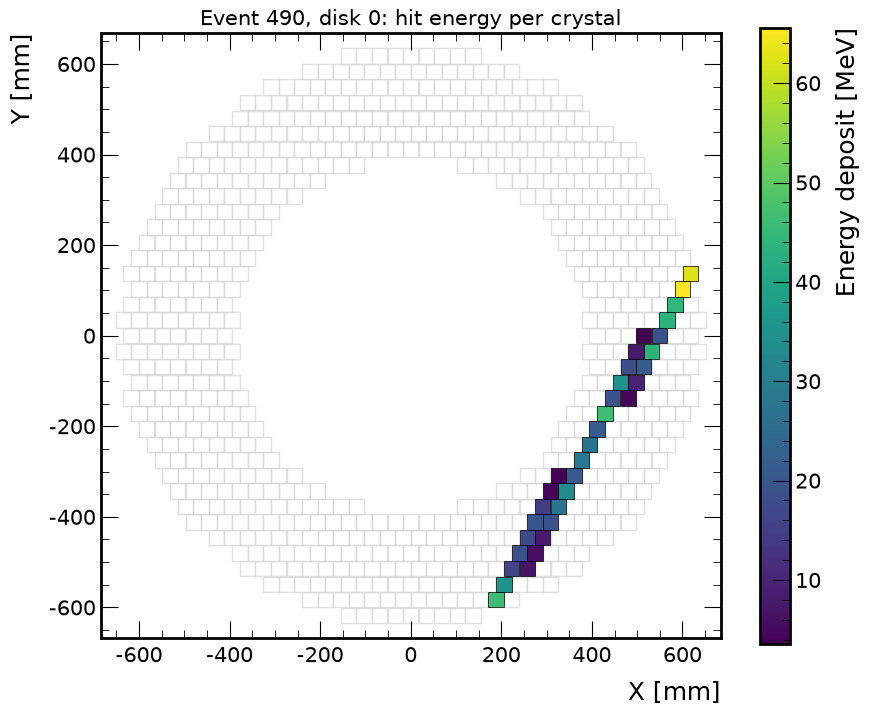

In [9]:
# Sum the hit energy in each crystal
hit_crystals = ak.to_numpy(data["calohits.crystalId_"][evt_idx])
hit_energies = ak.to_numpy(data["calohits.eDep_"][evt_idx])
crystal_energy = np.bincount(hit_crystals, weights=hit_energies, minlength=1348)

# Crystals on this disk with energy
disk_data = calo_vis.crystals_by_disk[disk]
energy = crystal_energy[disk_data["cryID"].to_numpy()]
is_hit = energy > 0

fig, ax = plt.subplots(figsize=(10, 10))
calo_vis.plot_crystal_grid(ax, disk=disk, crystal_color="white", edge_color="lightgray")

# Draw the hit crystals coloured by energy
squares = [
    patches.Rectangle((x - 17, y - 17), 34, 34)
    for x, y in zip(disk_data["xcry"].to_numpy()[is_hit], disk_data["ycry"].to_numpy()[is_hit])
]
hit_patches = PatchCollection(squares, cmap="viridis", edgecolor="black", linewidth=0.5, zorder=10)
hit_patches.set_array(energy[is_hit])
ax.add_collection(hit_patches)
fig.colorbar(hit_patches, ax=ax, label="Energy deposit [MeV]", shrink=0.8)

calo_vis.set_2d_axis_limits(ax, disk=disk, margin=50)
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.set_title(f"Event {evt_idx}, disk {disk}: hit energy per crystal")
plt.show()

## 7. Linking data products

The calorimeter branches are linked by indices within each event, for example `calorecodigis.caloDigiIdx_` gives the raw digi each reco digi was made from. Awkward arrays can follow these links for all events at once, by indexing one jagged array with another:

In [10]:
# SiPM and crystal of each reco digi, via its raw digi
reco_sipm = data["calodigis.SiPMID_"][data["calorecodigis.caloDigiIdx_"]]
reco_crystal = reco_sipm // 2

print("Reco digi crystals, event", evt_idx, ":", reco_crystal[evt_idx][:10].tolist(), "...")

Reco digi crystals, event 490 : [253, 344, 345, 252, 253, 345, 344, 252, 437, 593] ...


These arrays work with the rest of `pyutils`, for example the reco digi energy spectrum with `pyplot`:

[pyplot] [INFO] Initialised Plot with mu2e.mplstyle and verbosity = 1


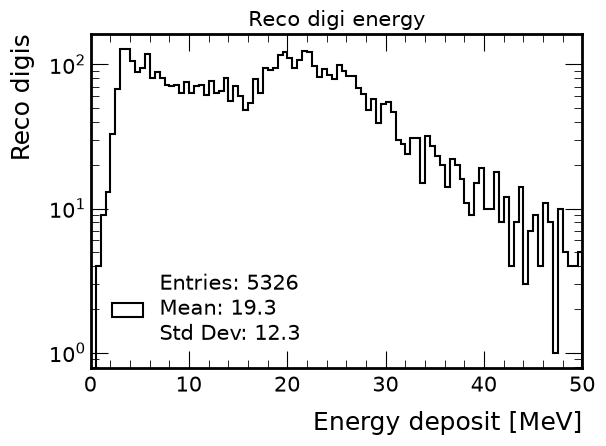

In [11]:
plotter = Plot()

plotter.plot_1D(
    ak.flatten(data["calorecodigis.eDep_"]),
    nbins=100,
    xmin=0,
    xmax=50,
    log_y=True,
    title="Reco digi energy",
    xlabel="Energy deposit [MeV]",
    ylabel="Reco digis",
)

## Summary

This notebook showed how to:

1. Load and draw the calorimeter crystal map with `CrystalMap`
2. Overlay the calibration source pipes with `PipeGeometry`
3. Read calorimeter branches from a large file without loading it all
4. Make event displays with `CaloVisualization`
5. Build custom displays from the same building blocks
6. Follow links between calorimeter data products with awkward arrays

For a command-line version of the event display, see [calo_event_display.py](../scripts/calo_event_display.py).